# Medial temporal lobe contributions to scene memory across a one-week delay
## Angelique I. Delarazan, Alexis N. Garcia, Matthew D. Grilli
### Scene360Recall_FiguresTables

# Set Up

## Import Packages

In [37]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mc
import seaborn as sns

## Load Data

In [ ]:
base = '/Volumes/Achieve/R03/aidelarazan/GitHub_OSF/Scene360Recall/'
data = pd.read_csv(os.path.join(base, "Data/sub-all_task-Scene360Recall_desc-Data.csv"))
neuropsych = pd.read_csv(os.path.join(base, "Data/sub-all_task-Scene360Recall_desc-Neuropsych.csv"))
data.head()

,Subject,Session,Scene,SceneOrder,WordCount,DescriptionSimilarity,ConsensusSimilarity,SelfConsistency,AI_InternalDetails,AI_ExternalDetails,...,AI_SemanticAutobiograhicalDetails,AI_SemanticGeneralDetails,AI_SemanticPlaceDetails,AI_SemanticTimeDetails,MTL,Hippocampus,ERC,PHC,PRC,Age
0,CAS035,1,CityStreets,2,202.0,0.203298,0.396013,0.625806,13.0,3.0,...,0.0,1.0,0.0,0,0.45405,-0.223432,2.794078,-0.665359,-0.7283,66
1,CAS035,2,CityStreets,2,246.0,0.396283,0.557538,0.625806,17.0,0.5,...,0.0,0.0,0.0,0,0.45405,-0.223432,2.794078,-0.665359,-0.7283,66
2,CAS035,1,Distillery,3,246.0,0.406231,0.592915,0.819268,17.0,5.0,...,0.0,0.0,0.0,0,0.45405,-0.223432,2.794078,-0.665359,-0.7283,66
3,CAS035,2,Distillery,3,218.0,0.417042,0.617837,0.819268,13.0,3.5,...,0.0,0.0,0.0,0,0.45405,-0.223432,2.794078,-0.665359,-0.7283,66
4,CAS035,1,FrenchTown,4,108.0,0.347109,0.493031,0.675641,10.5,1.0,...,0.0,0.0,0.0,0,0.45405,-0.223432,2.794078,-0.665359,-0.7283,66


## Helpers

In [26]:
"""
Figure helpers for the scene memory paper.

Three panel types:
    paired_panel()   box + points + within-subject lines, Session 1 vs 2
    single_panel()   box + points, one distribution (Self-Consistency)
    corr_panel()     scatter + OLS fit, optionally split by session

All panels share styling so they can sit side by side.
"""

# ---------------------------------------------------------------- colors

def tint(color, pct=0.30):
    """pct lighter, mixing toward white in RGB."""
    r, g, b = mc.to_rgb(color)
    return (r + (1 - r) * pct, g + (1 - g) * pct, b + (1 - b) * pct)


def shade(color, pct=0.30):
    """pct darker, mixing toward black."""
    r, g, b = mc.to_rgb(color)
    return (r * (1 - pct), g * (1 - pct), b * (1 - pct))


# ---------------------------------------------------------------- shared

FONTSIZE = 8
BOX_EDGE = '0.3'
BOX_ALPHA = 0.25
PT_SIZE = 14
PT_ALPHA = 0.6
LINE_A = 0.2

# bracket geometry, as a fraction of the y-axis range
SIG_FRAC = 0.93      # height of the bar
SIG_H_FRAC = 0.015   # length of the downward ticks

# default headroom when ylim is auto, as a fraction of the data range
PAD_LO, PAD_HI = 0.08, 0.22


def _auto_ylim(values, pad_lo=PAD_LO, pad_hi=PAD_HI):
    dmin, dmax = np.min(values), np.max(values)
    span = dmax - dmin
    return (dmin - span * pad_lo, dmax + span * pad_hi)


def _style_boxes(ax, edge=BOX_EDGE, alpha=BOX_ALPHA):
    """Apply fill alpha and outline color (seaborn overrides boxprops)."""
    for patch in list(ax.artists) + list(ax.patches):
        fc = patch.get_facecolor()
        patch.set_facecolor((fc[0], fc[1], fc[2]))
        patch.set_alpha(alpha)
        patch.set_edgecolor(edge)
        patch.set_linewidth(1)


def _bracket(ax, text, x0=0, x1=1, frac=SIG_FRAC, h_frac=SIG_H_FRAC, pad=0.0):
    """Draw a significance bracket at a fixed fraction of the y-range."""
    lo, hi = ax.get_ylim()
    span = hi - lo
    y = lo + span * frac
    h = span * h_frac
    ax.plot([x0, x0, x1, x1], [y, y + h, y + h, y],
            color='black', linewidth=0.8)
    ax.text((x0 + x1) / 2, y + h + pad, text,
            ha='center', va='bottom', fontsize=FONTSIZE)


def _finish(ax, ylim, yticks, xticks, xticklabels, xlabel, ylabel,
            xlim, despine_bottom=False):
    ax.set_xlabel(xlabel if xlabel else '', fontsize=FONTSIZE)
    ax.set_ylabel(ylabel, fontsize=FONTSIZE)
    if xticks is not None:
        ax.set_xticks(xticks)
        if xticklabels is not None:
            ax.set_xticklabels(xticklabels)
    ax.tick_params(labelsize=FONTSIZE)
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    if yticks is not None:
        ax.set_yticks(yticks)
    sns.despine(ax=ax, bottom=despine_bottom)


def _save(fig, savepath):
    if savepath:
        if not str(savepath).lower().endswith(('.png', '.pdf', '.svg')):
            savepath = f'{savepath}.png'
        fig.savefig(savepath, dpi=300, bbox_inches='tight', transparent=True)


# ---------------------------------------------------------------- panels

def paired_panel(
    data, measure, color, ylabel,
    color2=None, lighten=0.30,
    sig=None,
    ylim=None, yticks=None,
    line_color=None, line_a=LINE_A, line_w=0.7,
    pt_edge=None, pt_edge_w=0.4,
    subject_col='Subject', session_col='Session',
    session_labels=('Immediate', 'Delayed'),
    jitter=0.06, box_w=0.5, figsize=(3, 3),
    seed=0, savepath=None, ax=None,
):
    """Box + points + within-subject connecting lines across two sessions."""
    c1 = color
    c2 = color2 if color2 is not None else tint(color, lighten)

    subj = data.groupby([subject_col, session_col],
                        as_index=False)[measure].mean()
    wide = (subj.pivot(index=subject_col, columns=session_col, values=measure)
                .dropna())
    s1, s2 = sorted(wide.columns)
    y1, y2 = wide[s1].to_numpy(), wide[s2].to_numpy()

    rng = np.random.default_rng(seed)
    off = rng.uniform(-jitter, jitter, size=len(wide))

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, facecolor='none')
    else:
        fig = ax.figure
    ax.set_facecolor('none')

    subj = subj[subj[subject_col].isin(wide.index)].copy()
    subj['_x'] = subj[session_col].map({s1: 0, s2: 1})

    sns.boxplot(data=subj, x='_x', y=measure, ax=ax, palette=[c1, c2],
                width=box_w, showfliers=False, linewidth=1, zorder=0,
                whiskerprops=dict(color=BOX_EDGE, linewidth=1),
                capprops=dict(color=BOX_EDGE, linewidth=1),
                medianprops=dict(color=BOX_EDGE, linewidth=1.5))
    _style_boxes(ax)

    lc = line_color if line_color is not None else color
    for a, b, o in zip(y1, y2, off):
        ax.plot([o, 1 + o], [a, b], color=lc, alpha=line_a,
                linewidth=line_w, zorder=1)

    e1 = pt_edge if pt_edge is not None else c1
    e2 = pt_edge if pt_edge is not None else c2
    ax.scatter(off, y1, s=PT_SIZE, facecolor=c1, edgecolor=e1,
               linewidths=pt_edge_w, alpha=PT_ALPHA, zorder=2)
    ax.scatter(1 + off, y2, s=PT_SIZE, facecolor=c2, edgecolor=e2,
               linewidths=pt_edge_w, alpha=PT_ALPHA, zorder=2)

    if ylim is None:
        ylim = _auto_ylim(np.concatenate([y1, y2]))

    _finish(ax, ylim, yticks, [0, 1], list(session_labels),
            '', ylabel, (-0.6, 1.6))

    if sig:
        _bracket(ax, sig)

    _save(fig, savepath)
    return ax


def single_panel(
    data, measure, color, ylabel, xlabel='Across Sessions',
    dedupe_on=('Subject', 'Scene'), subject_col='Subject',
    ylim=None, yticks=None, pt_edge=None, pt_edge_w=0.4,
    jitter=0.06, box_w=0.5, figsize=(3, 3), xlim=(-1.1, 1.1),
    seed=0, savepath=None, ax=None,
):
    """Box + points for a single distribution (one value per subject)."""
    subj = (data.drop_duplicates(list(dedupe_on))
                .groupby(subject_col, as_index=False)[measure].mean())
    y = subj[measure].to_numpy()

    rng = np.random.default_rng(seed)
    x = rng.uniform(-jitter, jitter, size=len(y))

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, facecolor='none')
    else:
        fig = ax.figure
    ax.set_facecolor('none')

    sns.boxplot(y=subj[measure], ax=ax, color=color,
                width=box_w, showfliers=False, linewidth=1, zorder=0,
                whiskerprops=dict(color=BOX_EDGE, linewidth=1),
                capprops=dict(color=BOX_EDGE, linewidth=1),
                medianprops=dict(color=BOX_EDGE, linewidth=1.5))
    _style_boxes(ax)

    ax.scatter(x, y, s=PT_SIZE, facecolor=color,
               edgecolor=pt_edge if pt_edge is not None else color,
               linewidths=pt_edge_w, alpha=PT_ALPHA, zorder=2)

    if ylim is None:
        ylim = _auto_ylim(y)

    _finish(ax, ylim, yticks, [0], [xlabel], '', ylabel, xlim)
    _save(fig, savepath)
    return ax


def corr_panel(
    data, xvar, measure, color, xlabel, ylabel,
    by_session=True, color2=None, lighten=0.35,
    session_col='Session', subject_col='Subject',
    session_labels=('Immediate', 'Delayed'),
    dedupe_on=None,
    legend=True, legend_label='Across Sessions', legend_loc='lower right',
    band_alpha=0.15, line_w=1.5, pt_edge=None, pt_edge_w=0.4,
    xlim=None, ylim=None, yticks=None,
    figsize=(3, 3), savepath=None, ax=None,
):
    """Scatter + OLS fit of `measure` on `xvar`, optionally split by session.

    Note: OLS on subject means will not exactly reproduce LMM slopes.
    """
    c1 = color
    c2 = color2 if color2 is not None else tint(color, lighten)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, facecolor='none')
    else:
        fig = ax.figure
    ax.set_facecolor('none')

    if by_session:
        subj = (data.groupby([subject_col, session_col], as_index=False)
                    .agg({measure: 'mean', xvar: 'first'}))
        sessions = sorted(subj[session_col].unique())
        for sess, c, lab in zip(sessions, [c1, c2], session_labels):
            d = subj[subj[session_col] == sess]
            sns.regplot(data=d, x=xvar, y=measure, ax=ax, color=c,
                        ci=95, truncate=False,
                        scatter_kws=dict(s=PT_SIZE, alpha=PT_ALPHA,
                                         edgecolor=pt_edge if pt_edge
                                         is not None else c,
                                         linewidths=pt_edge_w),
                        line_kws=dict(linewidth=line_w, label=lab))
        allv = subj[measure].to_numpy()
    else:
        src = (data.drop_duplicates(list(dedupe_on))
               if dedupe_on else data)
        subj = (src.groupby(subject_col, as_index=False)
                   .agg({measure: 'mean', xvar: 'first'}))
        sns.regplot(data=subj, x=xvar, y=measure, ax=ax, color=c1,
                    ci=95, truncate=False,
                    scatter_kws=dict(s=PT_SIZE, alpha=PT_ALPHA,
                                     edgecolor=pt_edge if pt_edge
                                     is not None else c1,
                                     linewidths=pt_edge_w),
                    line_kws=dict(linewidth=line_w, label=legend_label))
        allv = subj[measure].to_numpy()

    for coll in ax.collections[1::2]:
        coll.set_alpha(band_alpha)

    if ylim is None:
        ylim = _auto_ylim(allv, pad_hi=PAD_LO)

    _finish(ax, ylim, yticks, None, None, xlabel, ylabel, xlim)

    if legend:
        ax.legend(fontsize=FONTSIZE - 1, frameon=False, loc=legend_loc)

    _save(fig, savepath)
    return ax

# Figures

## Internal Detail Proportion

<Axes: ylabel='Internal Detail Proportion'>

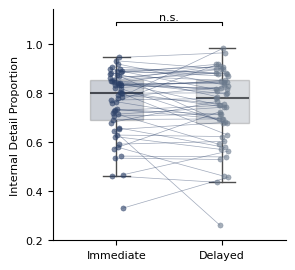

In [27]:
paired_panel(data, 'AI_InternalDetailsProportion', '#2a3f67',
             'Internal Detail Proportion',
             color2='#6b7a8d', sig='n.s.',
             line_a=0.45, line_w=0.5,
             yticks=[0.2, 0.4, 0.6, 0.8, 1.0],
             savepath=None)
            #  savepath=('os.path.join(base, "Figures/Scene360Recall_Fig2A_InternalDetailProportion'))

## Description Similarity

<Axes: ylabel='Description Similarity'>

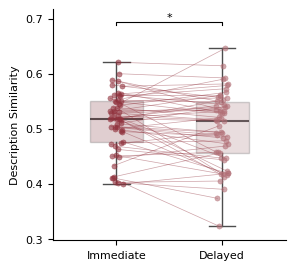

In [28]:
paired_panel(data, 'DescriptionSimilarity', '#91323d', 'Description Similarity',
             color2='#b27077', sig='*',
             line_a=0.45, line_w=0.5,
            yticks=[0.3, 0.4, 0.5, 0.6, 0.7],
            savepath=None)
            #  savepath=('os.path.join(base, "Figures/Scene360Recall_Fig2B_DescriptionSimilarity')

## Consensus Similarity

<Axes: ylabel='Consensus Similarity'>

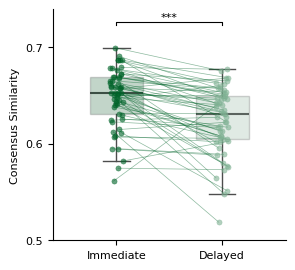

In [ ]:
paired_panel(data, 'ConsensusSimilarity', '#006429', 'Consensus Similarity',
             color2='#80B294', sig='***',
             line_a=0.45, line_w=0.5,
            yticks=[0.5, 0.6, 0.7],
            savepath=None)
            #  savepath=('os.path.join(base, "Figures/Scene360Recall_Fig2C_ConsensusSimilarity')

## Self-Consistency

<Axes: ylabel='Self-Consistency'>

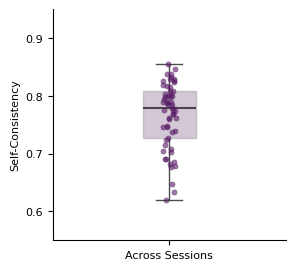

In [ ]:
single_panel(data, 'SelfConsistency', '#571a65', 'Self-Consistency',
             ylim=(0.55, 0.95),
             yticks=[0.6, 0.7, 0.8, 0.9],
             savepath=None)
            #  savepath=('os.path.join(base, "Figures/Scene360Recall_Fig2D_SelfSimilarity')

## MTL and Internal Detail Proportion

<Axes: xlabel='MTL Volume', ylabel='Internal Detail Proportion'>

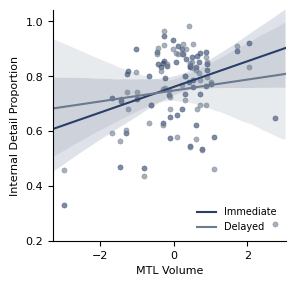

In [ ]:
corr_panel(data, 'MTL', 'AI_InternalDetailsProportion', '#2a3f67',
           'MTL Volume', 'Internal Detail Proportion',
           color2='#6b7a8d',
                        yticks=[0.2, 0.4, 0.6, 0.8, 1.0],
            savepath=None)
            #  savepath=('os.path.join(base, "Figures/Scene360Recall_Fig3B_MTLInternalDetailProportion')

## MTL and Description Similarity

<Axes: xlabel='MTL Volume', ylabel='Description Similarity'>

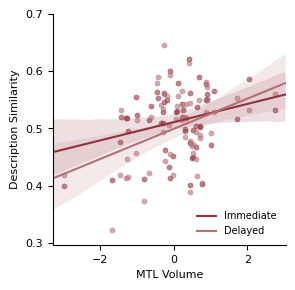

In [32]:
corr_panel(data, 'MTL', 'DescriptionSimilarity', '#91323d',
           'MTL Volume', 'Description Similarity',
           color2='#b27077',
                       yticks=[0.3, 0.4, 0.5, 0.6, 0.7],
            savepath=None)
        #    savepath=('os.path.join(base, "Figures/Scene360Recall_Fig3C_MTLDescriptionSimilarity')

## MTL and Consensus Similarity

<Axes: xlabel='MTL Volume', ylabel='Consensus Similarity'>

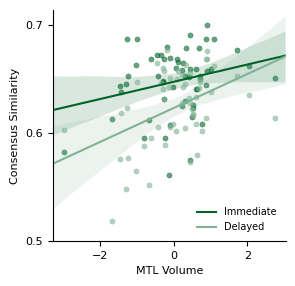

In [ ]:
corr_panel(data, 'MTL', 'ConsensusSimilarity', '#006429',
           'MTL Volume', 'Consensus Similarity',
                       yticks=[0.5, 0.6, 0.7],
                       color2='#80B294',
                       savepath=None)
            #  savepath=('os.path.join(base, "Figures/Scene360Recall_Fig3D_MTLConsensusSimilarity')

## MTL and Self-Consistency

<Axes: xlabel='MTL Volume', ylabel='Self-Consistency'>

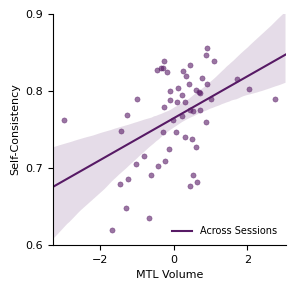

In [ ]:
corr_panel(data, 'MTL', 'SelfConsistency', '#571a65',
           'MTL Volume', 'Self-Consistency',
                        yticks=[0.6, 0.7, 0.8, 0.9],
           by_session=False, dedupe_on=('Subject', 'Scene'),
           savepath=None)
            #  savepath=('os.path.join(base, "Figures/Scene360Recall_Fig3E_MTLSelfSimilarity')

# Tables

## Neuropsychological Tests

In [44]:
print(neuropsych.describe())
num = neuropsych.select_dtypes("number")

tbl = pd.DataFrame({
    "Measure": num.columns,
    "N":  num.count().values,
    "M":  num.mean().round(2).values,
    "SD": num.std().round(2).values,
    "Min": num.min().values,
    "Max": num.max().values,
})
# tbl.to_csv(os.path.join(base, "Data/sub-all_task-Scene360Recall_desc-Table1NeuropsychologicalTests.csv", index=False))
tbl

       Unnamed: 0  cvlt_ldfr_raw  cvlt_ldfr_z  cvltt15_raw  cvltt15_z  \
count   57.000000      57.000000    57.000000    57.000000  57.000000   
mean    31.771930      11.631579     0.684211    50.701754   0.900000   
std     18.855671       3.298439     0.989370    10.055142   0.925241   
min      1.000000       4.000000    -1.500000    31.000000  -1.200000   
25%     16.000000       9.000000     0.000000    46.000000   0.300000   
50%     32.000000      12.000000     1.000000    51.000000   0.900000   
75%     47.000000      14.000000     1.500000    58.000000   1.600000   
max     66.000000      16.000000     2.500000    72.000000   2.700000   

         bnt_raw      bnt_z  anfluency_raw  anfluency_z  trailsa_raw  \
count  57.000000  57.000000      57.000000    57.000000    57.000000   
mean   57.894737   0.911404      22.263158     0.398246    32.075439   
std     1.858227   0.895204       4.966050     0.916221     9.332503   
min    52.000000  -1.000000      14.000000    -1.40000

,Measure,N,M,SD,Min,Max
0,Unnamed: 0,57,31.77,18.86,1.0,66.0
1,cvlt_ldfr_raw,57,11.63,3.30,4.0,16.0
2,cvlt_ldfr_z,57,0.68,0.99,-1.5,2.5
3,cvltt15_raw,57,50.70,10.06,31.0,72.0
4,cvltt15_z,57,0.90,0.93,-1.2,2.7
5,bnt_raw,57,57.89,1.86,52.0,60.0
6,bnt_z,57,0.91,0.90,-1.0,2.4
7,anfluency_raw,57,22.26,4.97,14.0,35.0
8,anfluency_z,57,0.40,0.92,-1.4,2.5
9,trailsa_raw,57,32.08,9.33,12.0,63.0


## Autobiographical Interview Scoring

In [ ]:
d = data.copy()

internal = {
    "AI_EventDetails":      "Event",
    "AI_PlaceDetails":      "Place",
    "AI_TimeDetails":       "Time",
    "AI_PerceptualDetails": "Perceptual",
    "AI_ThoughtEmotion":    "Thought/Emotion",
}
external = {
    "AI_SemanticAutobiograhicalDetails": "Semantic (autobiographical)",
    "AI_SemanticGeneralDetails":         "Semantic (general)",
    "AI_SemanticPlaceDetails":           "Semantic (place)",
    "AI_SemanticTimeDetails":            "Semantic (time)",
    "AI_RepetitionDetails":              "Repetition",
    "AI_MetacognitionDetails":           "Metacognitive",
}
totals = {
    "AI_InternalDetails":           "Total internal details",
    "AI_ExternalDetails":           "Total external details",
    "AI_TotalDetails":              "Total details",
    "AI_InternalDetailsProportion": "Internal detail proportion",
    "AI_FalseMemories":             "False memories",
}

def summarize(df, cols, category, by_session=True):
    keys = ["Subject", "Session"] if by_session else ["Subject"]
    subj = df.groupby(keys)[list(cols)].mean().reset_index()
    rows = []
    for col, label in cols.items():
        if by_session:
            entry = {"Category": category, "Detail Type": label}
            for s, tag in [(1, "Session 1"), (2, "Session 2")]:
                v = subj.loc[subj.Session == s, col]
                entry[f"{tag} M (SD)"] = f"{v.mean():.2f} ({v.std():.2f})"
                entry[f"{tag} Min"] = round(v.min(), 2)
                entry[f"{tag} Max"] = round(v.max(), 2)
            rows.append(entry)
        else:
            v = subj[col]
            rows.append({"Category": category, "Detail Type": label,
                         "M (SD)": f"{v.mean():.2f} ({v.std():.2f})",
                         "Min": round(v.min(), 2), "Max": round(v.max(), 2)})
    return pd.DataFrame(rows)

tbl = pd.concat([
    summarize(d, internal, "Internal"),
    summarize(d, external, "External"),
    summarize(d, totals,   "Summary"),
], ignore_index=True)

# tbl.to_csv(os.path.join(base, "Data/sub-all_task-Scene360Recall_desc-Table3AutobiographicalScoring.csv", index=False))
tbl

,Category,Detail Type,Session 1 M (SD),Session 1 Min,Session 1 Max,Session 2 M (SD),Session 2 Min,Session 2 Max
0,Internal,Event,7.29 (2.26),1.62,11.62,7.82 (2.98),2.75,15.50
1,Internal,Place,3.10 (2.86),0.00,9.31,3.13 (3.12),0.00,11.25
2,Internal,Time,0.25 (0.30),0.00,1.57,0.20 (0.29),0.00,1.19
3,Internal,Perceptual,12.88 (5.92),1.88,30.25,12.37 (7.37),2.81,36.75
4,Internal,Thought/Emotion,1.53 (1.45),0.00,6.00,1.76 (1.56),0.00,7.50
5,External,Semantic (autobiographical),0.35 (0.49),0.00,2.38,0.34 (0.57),0.00,2.62
6,External,Semantic (general),0.11 (0.32),0.00,1.88,0.07 (0.17),0.00,1.06
7,External,Semantic (place),0.01 (0.03),0.00,0.12,0.02 (0.06),0.00,0.25
8,External,Semantic (time),0.00 (0.03),0.00,0.25,0.00 (0.02),0.00,0.12
9,External,Repetition,1.68 (1.25),0.00,5.75,1.64 (1.23),0.00,6.50
